In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import scipy.stats

# Para que se muestren todas las columnas del DataFrame
pd.options.display.max_columns = 100 

In [2]:
df = pd.read_csv("C:/Users/carte/OneDrive/Documentos/MASTER IA/DATA SCIENCE/PRACTICA/PRACTICA 2/datos/diabetes.csv")
df.head(5)

,race,gender,age,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,primary_diagnosis,number_diagnoses,max_glu_serum,A1Cresult,insulin,change,diabetesMed,medicare,medicaid,had_emergency,had_inpatient_days,had_outpatient_days,readmitted,readmit_binary,readmit_30_days
0,Caucasian,Female,30 years or younger,Other,Referral,1,Other,41,0,1,Diabetes,1,NaN,NaN,No,No,No,False,False,False,False,False,NO,0,0
1,Caucasian,Female,30 years or younger,Discharged to Home,Emergency,3,Missing,59,0,18,Other,9,NaN,NaN,Up,Ch,Yes,False,False,False,False,False,>30,1,0
2,AfricanAmerican,Female,30 years or younger,Discharged to Home,Emergency,2,Missing,11,5,13,Other,6,NaN,NaN,No,No,Yes,False,False,False,True,True,NO,0,0
3,Caucasian,Male,30-60 years,Discharged to Home,Emergency,2,Missing,44,1,16,Other,7,NaN,NaN,Up,Ch,Yes,False,False,False,False,False,NO,0,0
4,Caucasian,Male,30-60 years,Discharged to Home,Emergency,1,Missing,51,0,8,Other,5,NaN,NaN,Steady,Ch,Yes,False,False,False,False,False,NO,0,0


## ANÁLISIS UNIVARIANTE

### Identificación y tratamiento de nulos

In [4]:
#identificación de nulos
print(df.isnull().sum())

race                            0
gender                          0
age                             0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
primary_diagnosis               0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
insulin                         0
change                          0
diabetesMed                     0
medicare                        0
medicaid                        0
had_emergency                   0
had_inpatient_days              0
had_outpatient_days             0
readmitted                      0
readmit_binary                  0
readmit_30_days                 0
dtype: int64


In [5]:
#identificación de nulos en porcentaje
df.isna().mean()*100

race                         0.000000
gender                       0.000000
age                          0.000000
discharge_disposition_id     0.000000
admission_source_id          0.000000
time_in_hospital             0.000000
medical_specialty            0.000000
num_lab_procedures           0.000000
num_procedures               0.000000
num_medications              0.000000
primary_diagnosis            0.000000
number_diagnoses             0.000000
max_glu_serum               94.746772
A1Cresult                   83.277322
insulin                      0.000000
change                       0.000000
diabetesMed                  0.000000
medicare                     0.000000
medicaid                     0.000000
had_emergency                0.000000
had_inpatient_days           0.000000
had_outpatient_days          0.000000
readmitted                   0.000000
readmit_binary               0.000000
readmit_30_days              0.000000
dtype: float64

In [6]:
# Sustituir nulos por categoría
df["max_glu_serum"] = df["max_glu_serum"].fillna("Desconocido")
df["A1Cresult"] = df["A1Cresult"].fillna("Desconocido")

In [7]:
df.isna().mean()*100

race                        0.0
gender                      0.0
age                         0.0
discharge_disposition_id    0.0
admission_source_id         0.0
time_in_hospital            0.0
medical_specialty           0.0
num_lab_procedures          0.0
num_procedures              0.0
num_medications             0.0
primary_diagnosis           0.0
number_diagnoses            0.0
max_glu_serum               0.0
A1Cresult                   0.0
insulin                     0.0
change                      0.0
diabetesMed                 0.0
medicare                    0.0
medicaid                    0.0
had_emergency               0.0
had_inpatient_days          0.0
had_outpatient_days         0.0
readmitted                  0.0
readmit_binary              0.0
readmit_30_days             0.0
dtype: float64

Se analizaron los valores nulos del dataset calculando el número absoluto y el porcentaje de valores faltantes por variable. Se observó que únicamente las variables max_glu_serum (94.75%) y A1Cresult (83.28%) presentan valores nulos.

Estos valores no corresponden a errores de datos, sino a pruebas médicas que no se realizaron. Por este motivo, en lugar de eliminar las variables o los registros, se decidió reemplazar los valores nulos por la categoría "Desconocido".

### Análisis de variantes categóricas

In [8]:
df.dtypes

race                          str
gender                        str
age                           str
discharge_disposition_id      str
admission_source_id           str
time_in_hospital            int64
medical_specialty             str
num_lab_procedures          int64
num_procedures              int64
num_medications             int64
primary_diagnosis             str
number_diagnoses            int64
max_glu_serum                 str
A1Cresult                     str
insulin                       str
change                        str
diabetesMed                   str
medicare                     bool
medicaid                     bool
had_emergency                bool
had_inpatient_days           bool
had_outpatient_days          bool
readmitted                    str
readmit_binary              int64
readmit_30_days             int64
dtype: object

In [13]:
#cómo saber las variables categóricas, incluyendo las que tienen 2 valores
# columnas categóricas por tipo
category_columns = list(df.select_dtypes(include=['object','bool']).columns)

# columnas binarias (solo 2 valores)
binary_columns = [col for col in df.columns if df[col].nunique() == 2]

# unir ambas listas sin duplicados
category_columns = list(set(category_columns + binary_columns))

category_columns

C:\Users\carte\AppData\Local\Temp\ipykernel_29028\1276426379.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_columns = list(df.select_dtypes(include=['object','bool']).columns)


['age',
 'discharge_disposition_id',
 'readmit_binary',
 'race',
 'diabetesMed',
 'admission_source_id',
 'readmit_30_days',
 'had_inpatient_days',
 'primary_diagnosis',
 'medical_specialty',
 'max_glu_serum',
 'had_outpatient_days',
 'medicare',
 'medicaid',
 'had_emergency',
 'insulin',
 'change',
 'gender',
 'A1Cresult',
 'readmitted']

In [31]:
#para elimnar los espacios
for col in category_columns:
    # Convertir columna a str
    df[col] = df[col].astype(str)
    df[col] = df[col].str.strip()
    df[col] = df[col].str.replace(" ", "_")

In [32]:
df[category_columns].describe(include="all")

,age,discharge_disposition_id,readmit_binary,race,diabetesMed,admission_source_id,readmit_30_days,had_inpatient_days,primary_diagnosis,medical_specialty,max_glu_serum,had_outpatient_days,medicare,medicaid,had_emergency,insulin,change,gender,A1Cresult,readmitted
count,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,3,2,2,6,2,3,2,2,5,6,4,2,2,2,2,4,2,3,4,3
top,Over_60_years,Discharged_to_Home,0,Caucasian,Yes,Emergency,0,False,Other,Missing,Desconocido,False,False,False,False,No,No,Female,Desconocido,NO
freq,68541,60234,54864,76099,78363,57494,90409,67630,68512,49949,96420,85027,69327,98234,90383,47383,54755,54708,84748,54864


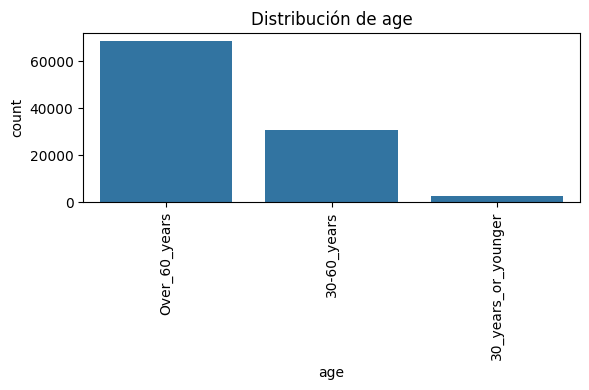

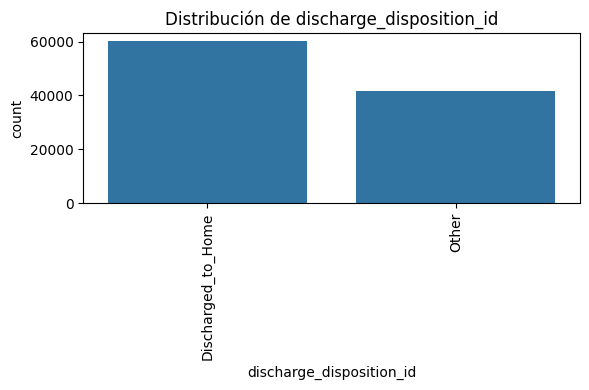

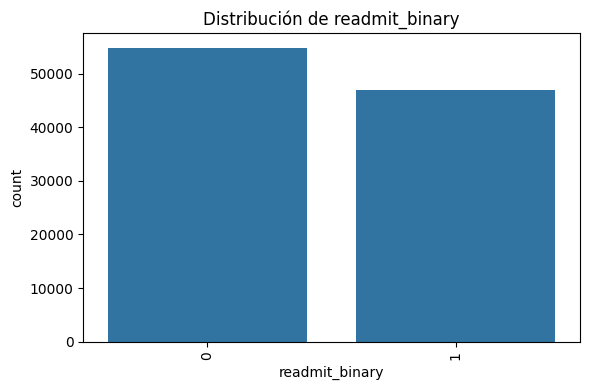

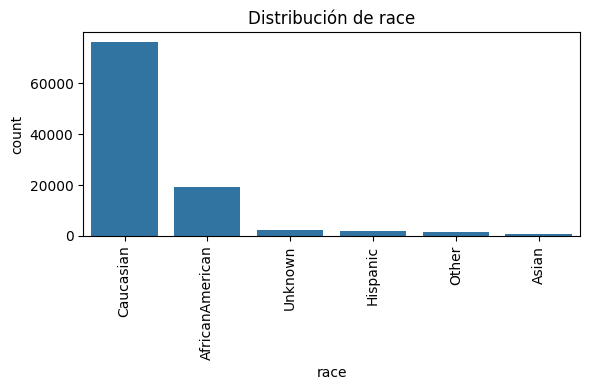

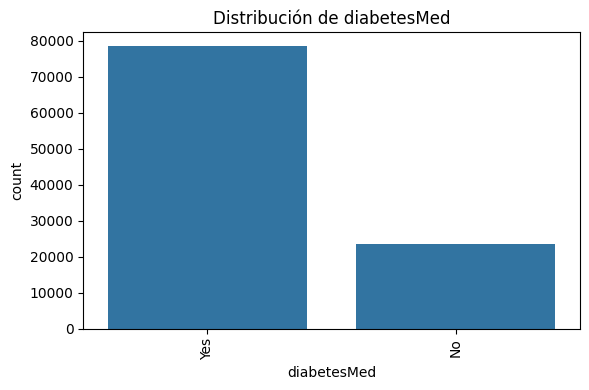

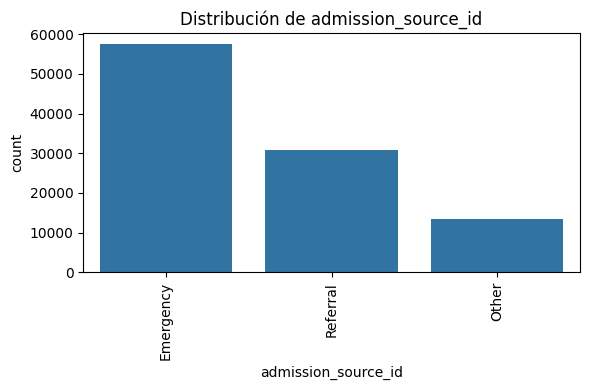

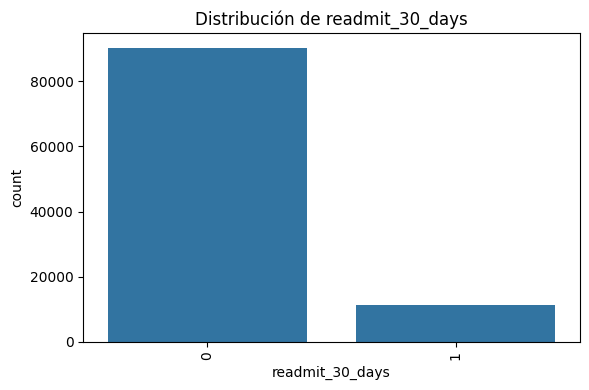

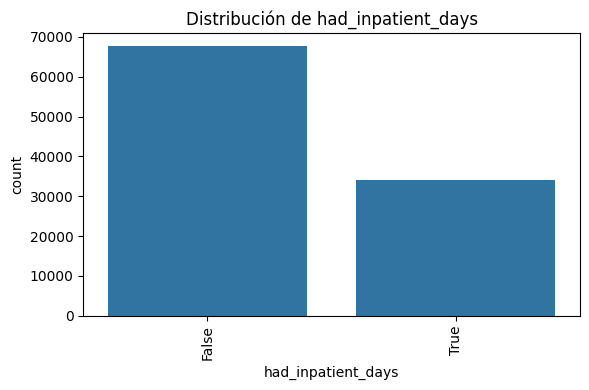

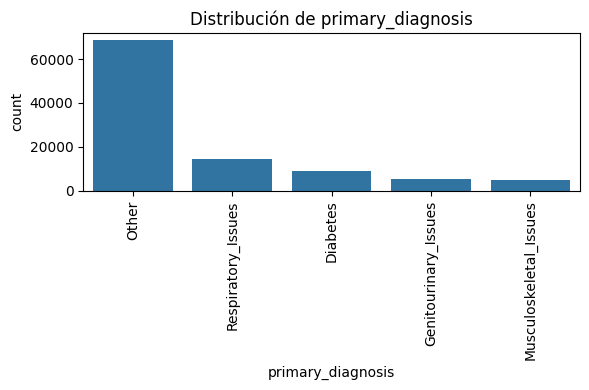

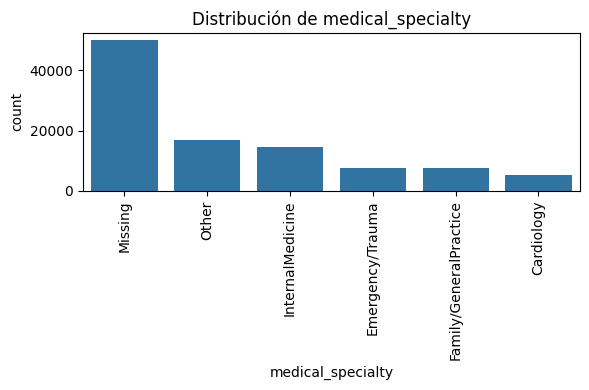

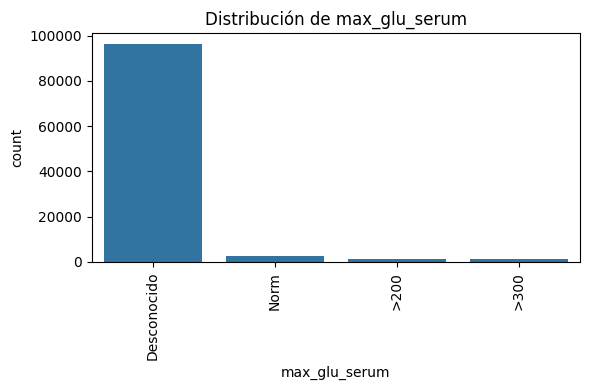

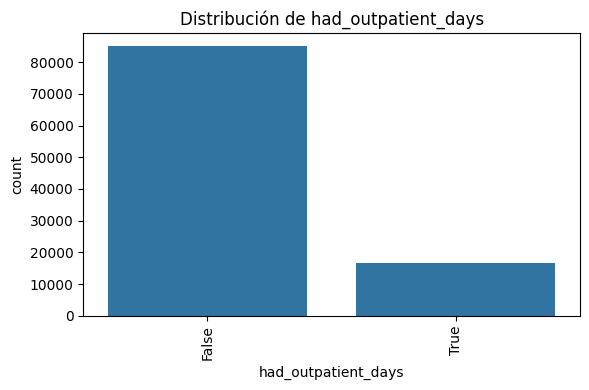

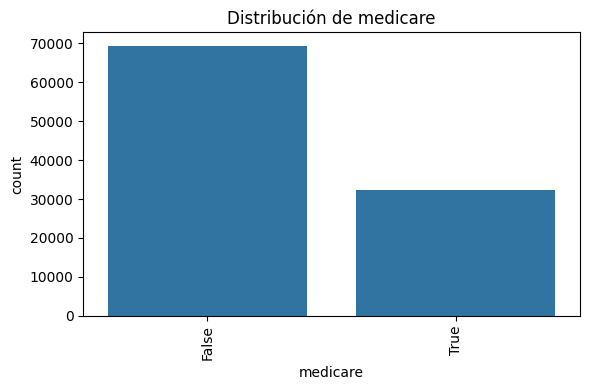

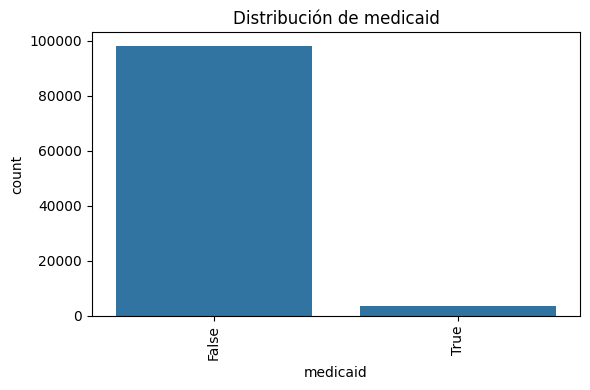

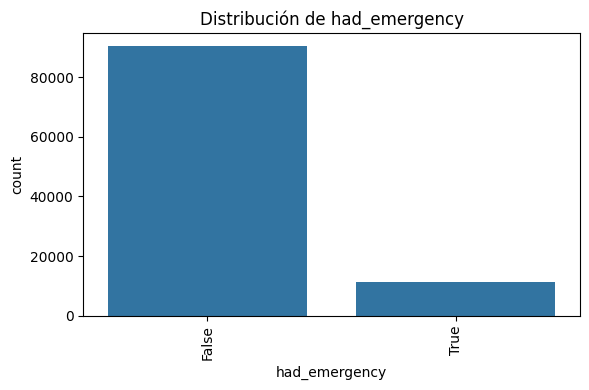

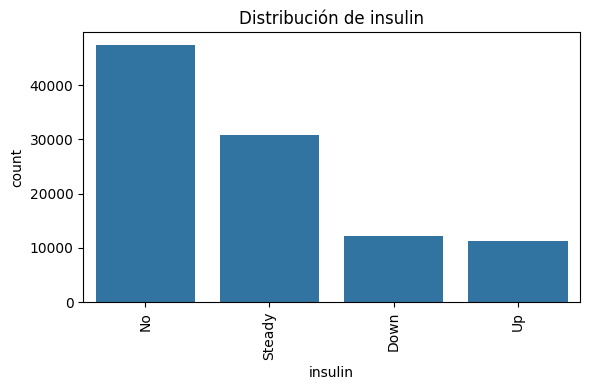

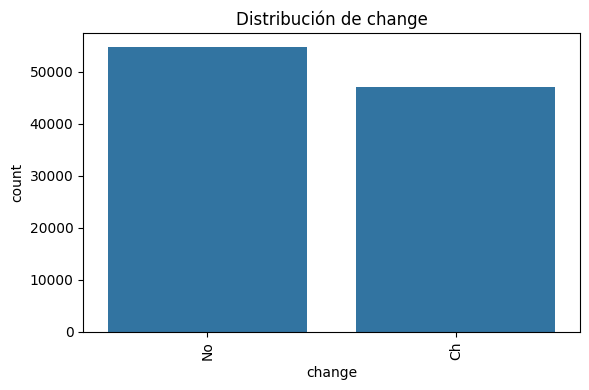

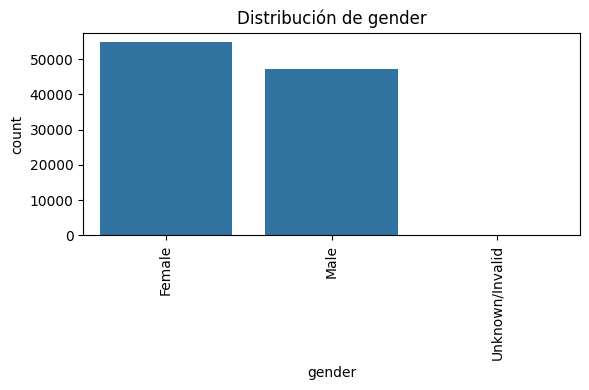

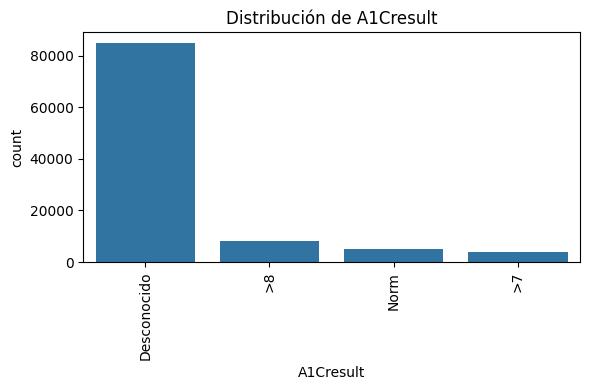

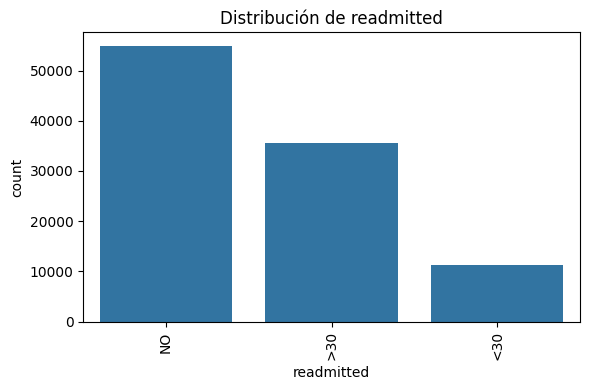

In [33]:
for col in category_columns:
    plt.figure(figsize=(6,4))
    sns.countplot(x=df[col], order=df[col].value_counts().index)
    plt.title(f"Distribución de {col}")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

En el análisis de las variables categóricas se observó que no existen columnas completamente constantes, aunque la variable medicaid presenta una distribución muy desequilibrada, ya que la gran mayoría de los registros corresponden al valor False, lo que indica una baja variabilidad. Asimismo, se detectaron variables con un número elevado de categorías o con distribuciones muy dominadas por una de ellas, como race, medical_specialty y primary_diagnosis, por lo que podría ser conveniente reducir o agrupar algunas categorías poco frecuentes para simplificar el análisis.

### Análisis de variantes numéricas

In [15]:
#qué variables son numéricas
numerical_columns = [x for x in df.columns if x not in category_columns]
numerical_columns

['time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_diagnoses']

In [21]:
df[numerical_columns].describe().round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses
count,101766.00,101766.00,101766.00,101766.00,101766.00
mean,4.40,43.10,1.34,16.02,7.42
std,2.99,19.67,1.71,8.13,1.93
min,1.00,1.00,0.00,1.00,1.00
25%,2.00,31.00,0.00,10.00,6.00
50%,4.00,44.00,1.00,15.00,8.00
75%,6.00,57.00,2.00,20.00,9.00
max,14.00,132.00,6.00,81.00,16.00


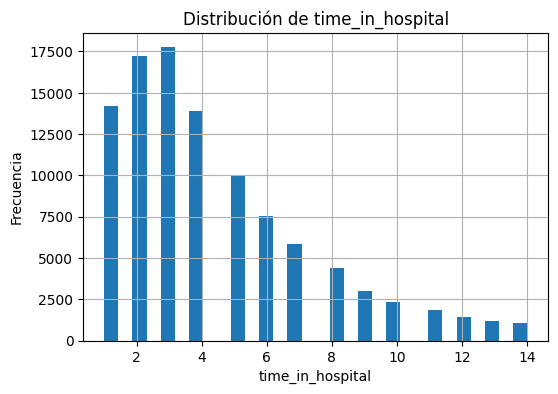

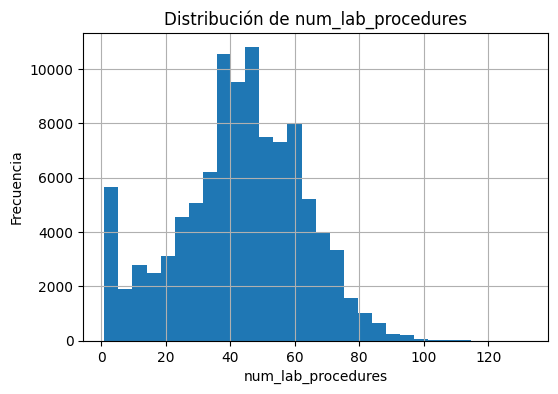

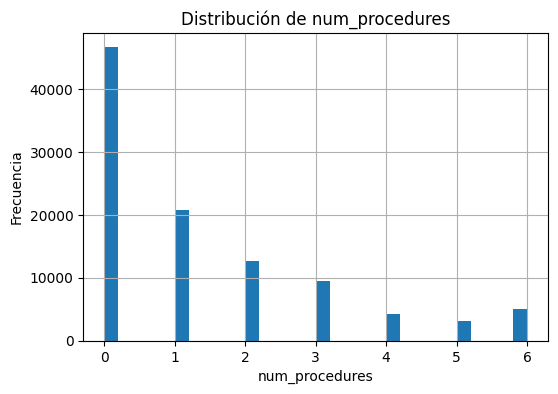

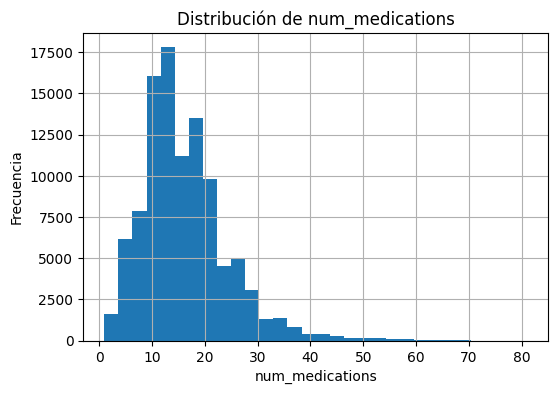

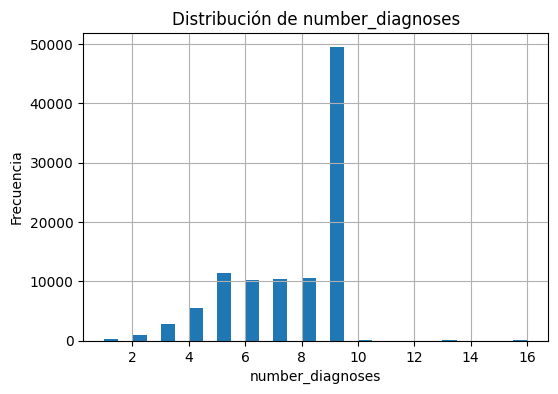

In [22]:
#para realizar los histogramas
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    df[col].hist(bins=30)
    plt.title(f"Distribución de {col}")
    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.show()

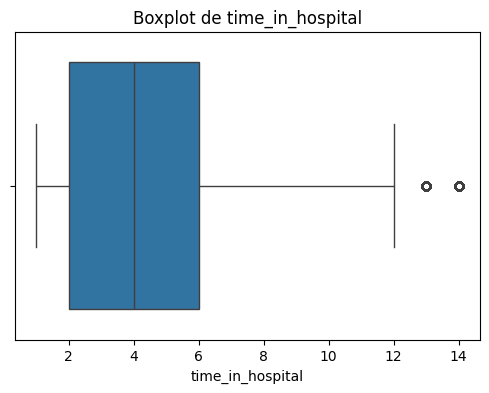

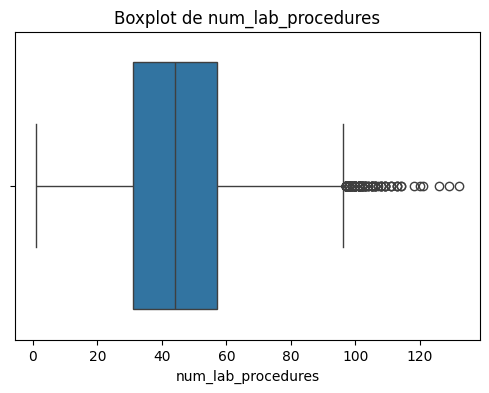

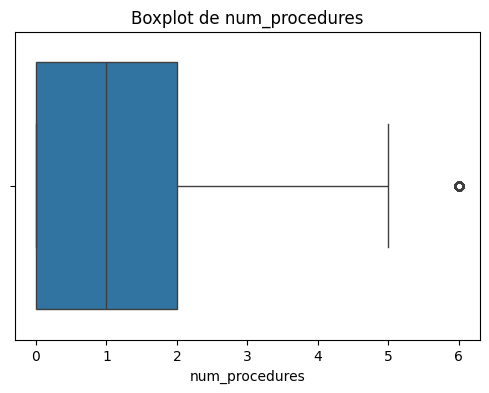

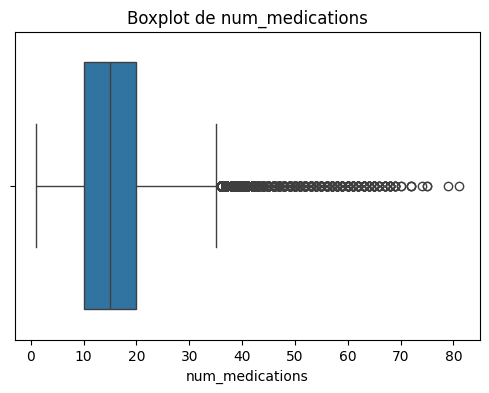

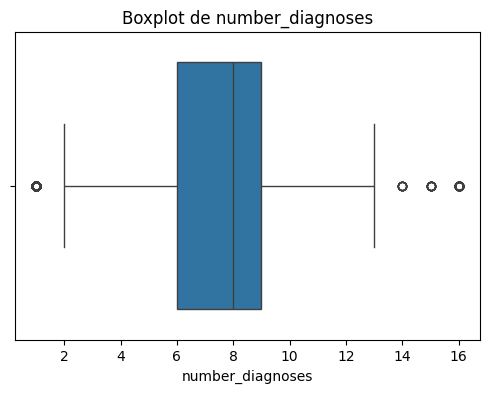

In [25]:
#para realizar los boxplots
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

Los valores atípicos observados en las variables numéricas corresponden principalmente a pacientes con mayor número de procedimientos, visitas médicas o diagnósticos. En este caso, dichos valores no parecen ser errores de registro, sino situaciones clínicas plausibles. Por ello, no se recomienda eliminarlos, ya que podrían contener información relevante para el análisis posterior y para la construcción de modelos predictivos.

## Análisis Multivariante

### Numérica vs Numérica

In [38]:
#vemos las correlaciones entre variables
corr_numerical = df[numerical_columns].corr()
corr_numerical.round(3)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses
time_in_hospital,1.000,0.318,0.191,0.466,0.220
num_lab_procedures,0.318,1.000,0.058,0.268,0.153
num_procedures,0.191,0.058,1.000,0.386,0.074
num_medications,0.466,0.268,0.386,1.000,0.262
number_diagnoses,0.220,0.153,0.074,0.262,1.000


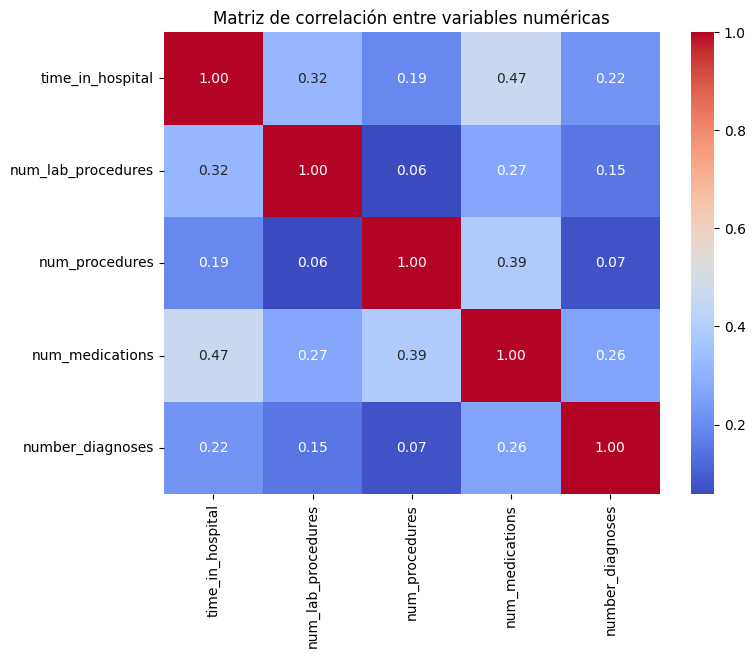

In [39]:
#hacemos el heatmap
plt.figure(figsize=(8,6))
sns.heatmap(corr_numerical,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

plt.title("Matriz de correlación entre variables numéricas")
plt.show()

En general, las correlaciones entre las variables numéricas son bajas o moderadas, lo que indica que cada variable aporta información diferente.La relación más destacada suele aparecer entre time_in_hospital y num_medications, ya que los pacientes que permanecen más tiempo hospitalizados suelen recibir más medicamentos.

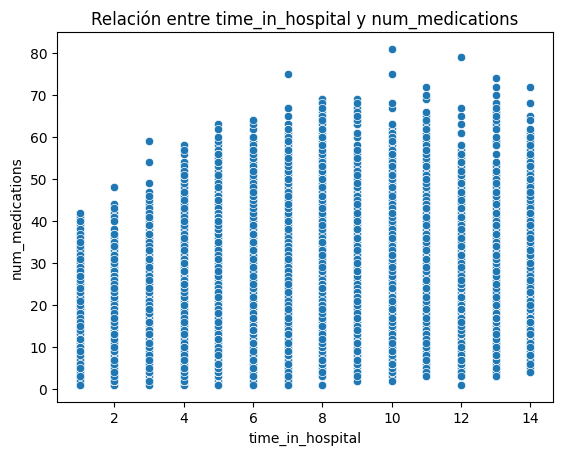

In [42]:
#hacemos el scatter plot de las variables con mas correlación
sns.scatterplot(x=df["time_in_hospital"], y=df["num_medications"])
plt.title("Relación entre time_in_hospital y num_medications")
plt.show()

### Numérica vs Categórica

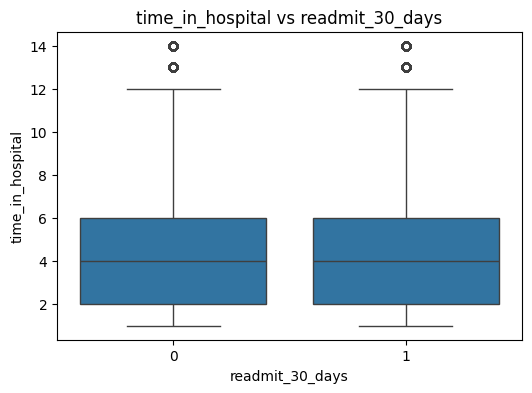

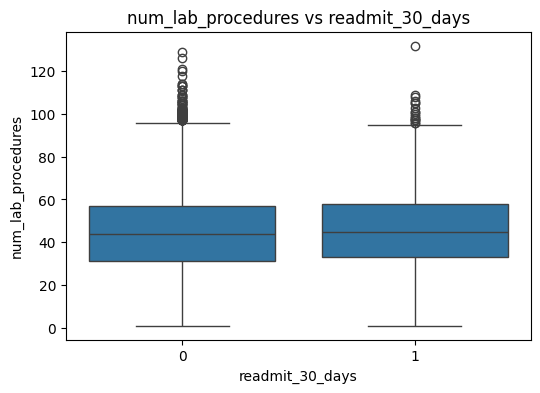

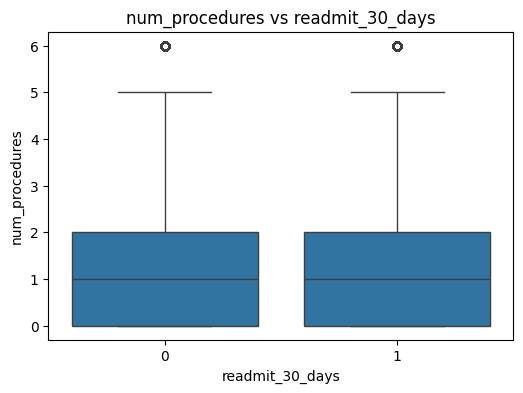

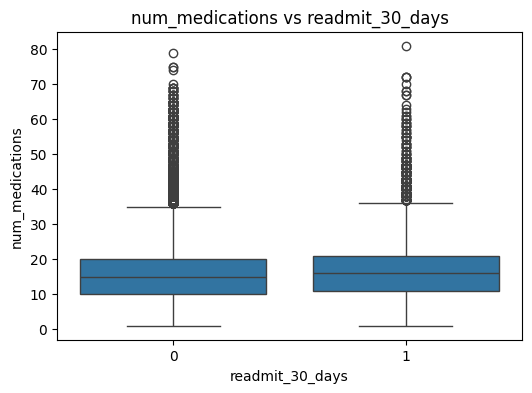

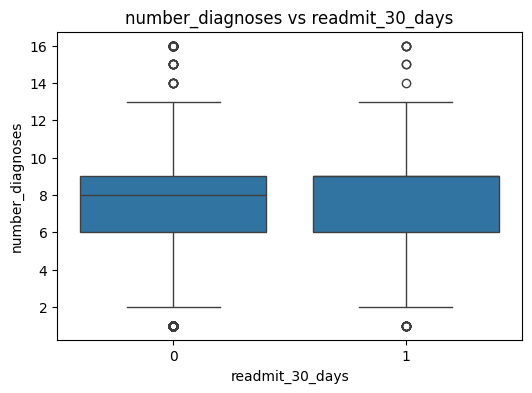

In [48]:
#hacemos los boxplots en relacion a la variable objetivo
for col in numerical_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df["readmit_30_days"], y=df[col])
    plt.title(f"{col} vs readmit_30_days")
    plt.xlabel("readmit_30_days")
    plt.ylabel(col)
    plt.show()

Se analizó la relación entre las variables numéricas y la variable objetivo readmit_30_days mediante boxplots. Los resultados muestran que algunas variables, como time_in_hospital, num_medications y number_diagnoses, presentan valores ligeramente mayores en pacientes readmitidos, lo que podría indicar que pacientes con estancias hospitalarias más largas, mayor número de medicamentos o mayor número de diagnósticos tienen una mayor probabilidad de ser readmitidos.

### Categórica vs Categórica

In [54]:
# hacemos la tabla de contingencia para cada variable
for col in category_columns:
    
    if col != "readmit_30_days":
        
        tabla = pd.crosstab(df[col], df["readmit_30_days"], normalize="index")
        
        print(f"Variable: {col}")
        print(tabla)
        print("-" * 50)

Variable: age
readmit_30_days             0         1
age                                    
30-60_years          0.898457  0.101543
30_years_or_younger  0.888800  0.111200
Over_60_years        0.883880  0.116120
--------------------------------------------------
Variable: discharge_disposition_id
readmit_30_days                  0         1
discharge_disposition_id                    
Discharged_to_Home        0.906996  0.093004
Other                     0.861432  0.138568
--------------------------------------------------
Variable: readmit_binary
readmit_30_days         0         1
readmit_binary                     
0                1.000000  0.000000
1                0.757857  0.242143
--------------------------------------------------
Variable: race
readmit_30_days         0         1
race                               
AfricanAmerican  0.887819  0.112181
Asian            0.898596  0.101404
Caucasian        0.887094  0.112906
Hispanic         0.895925  0.104075
Other            0

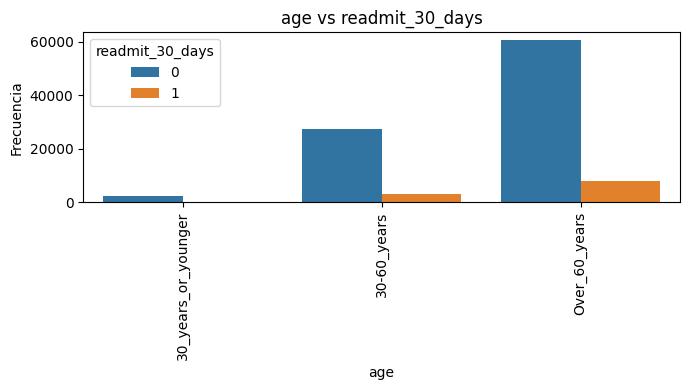

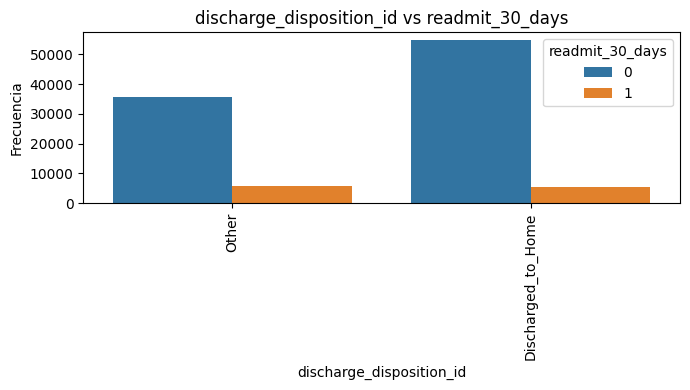

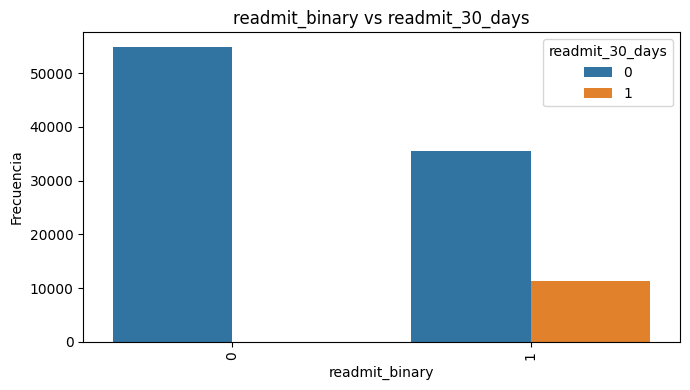

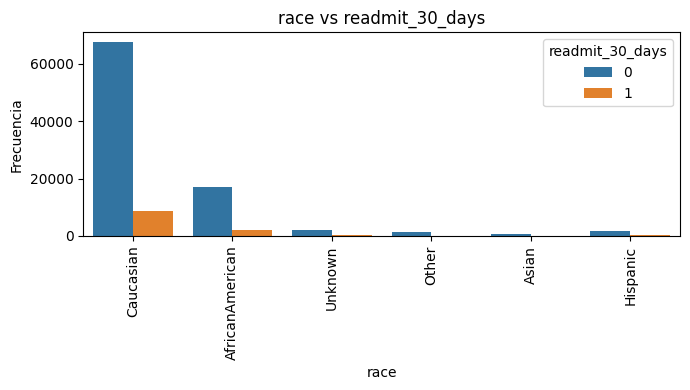

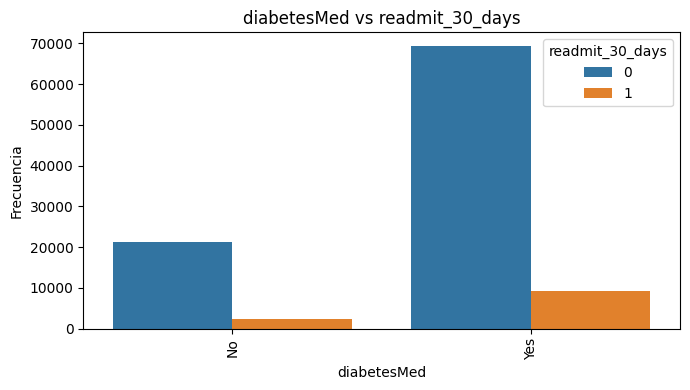

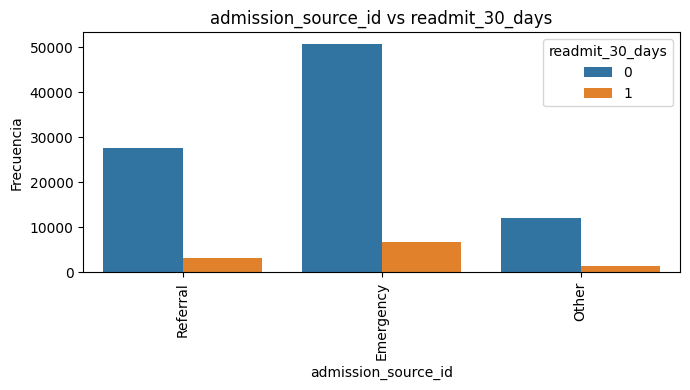

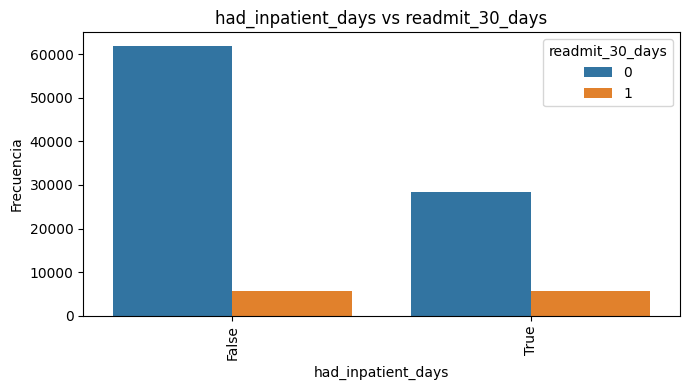

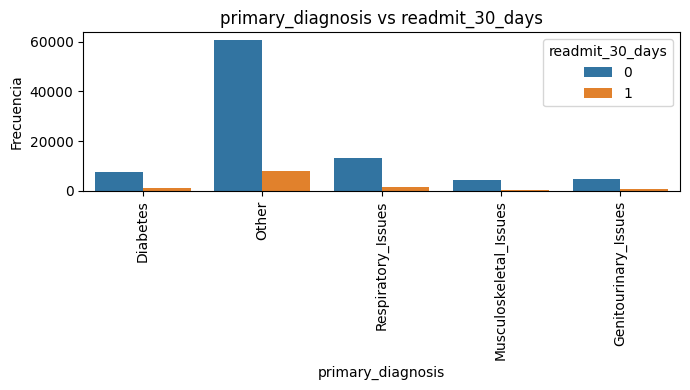

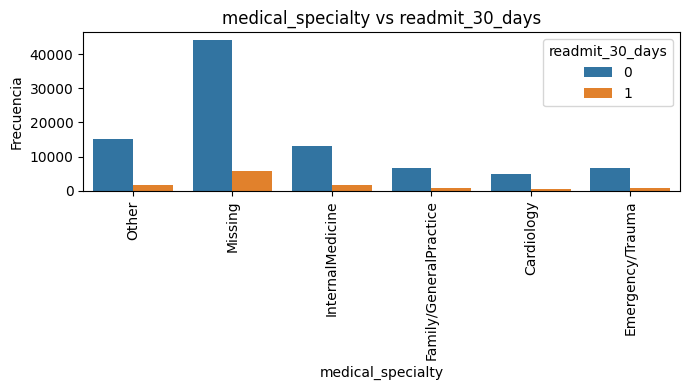

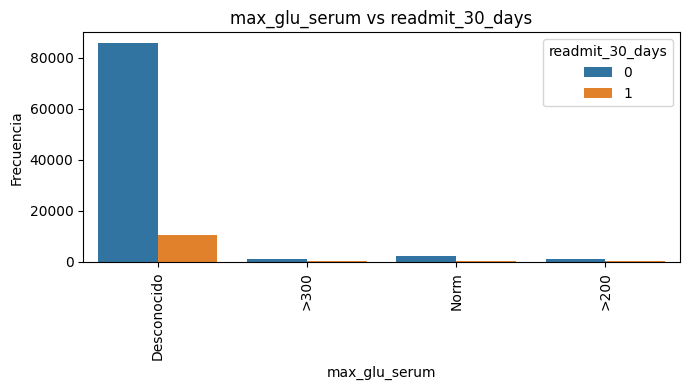

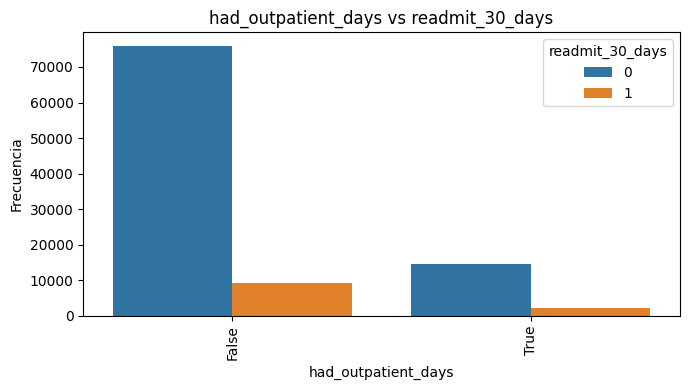

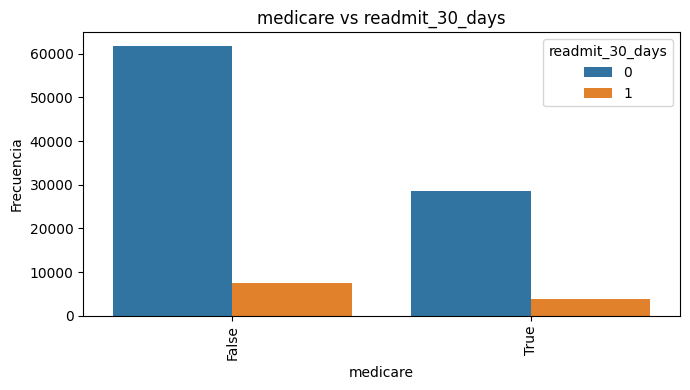

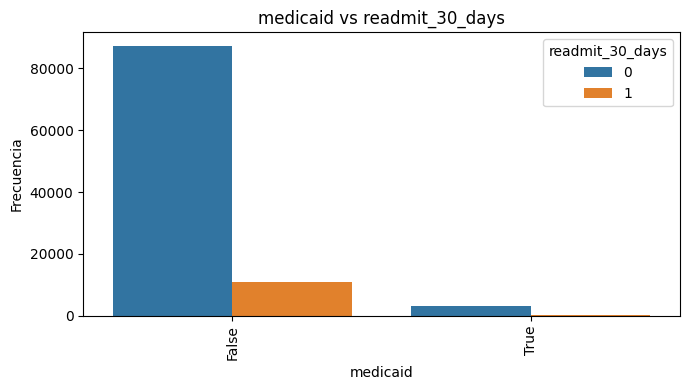

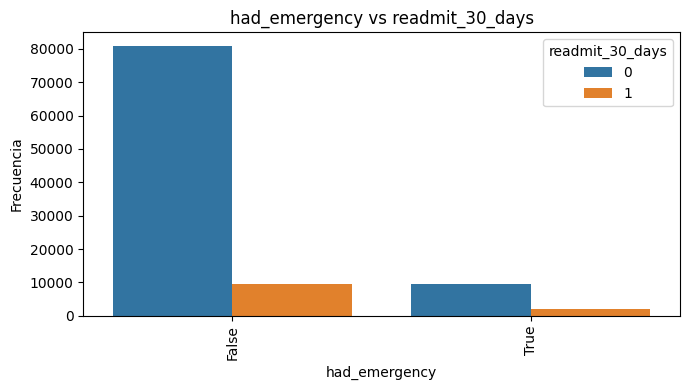

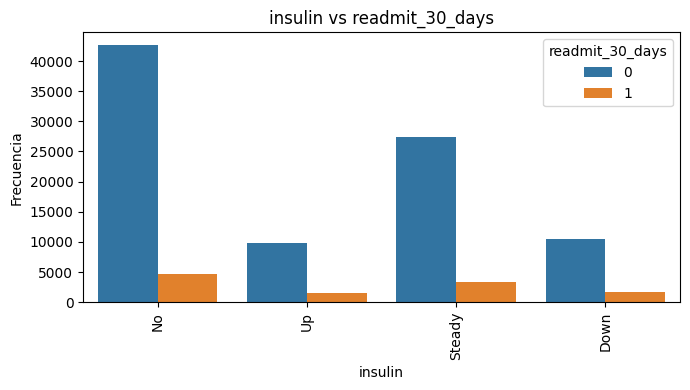

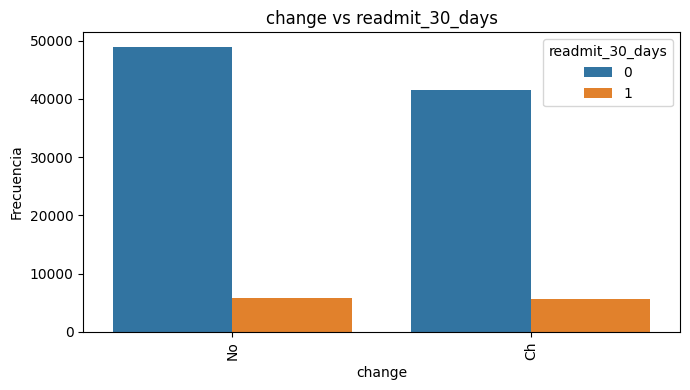

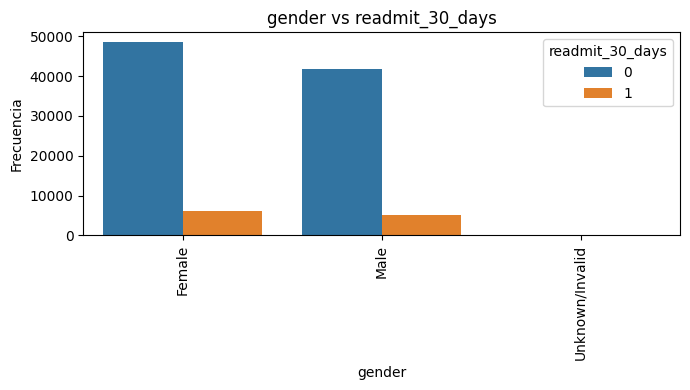

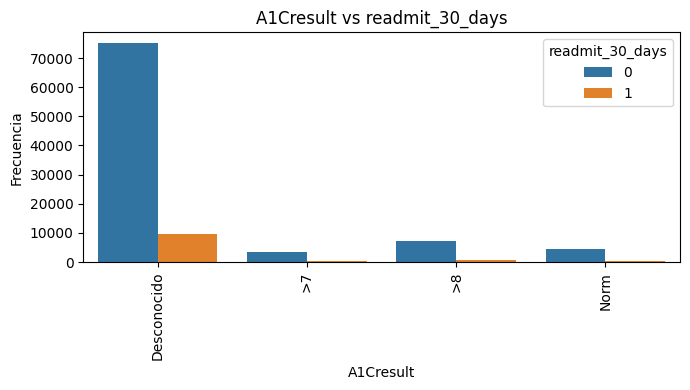

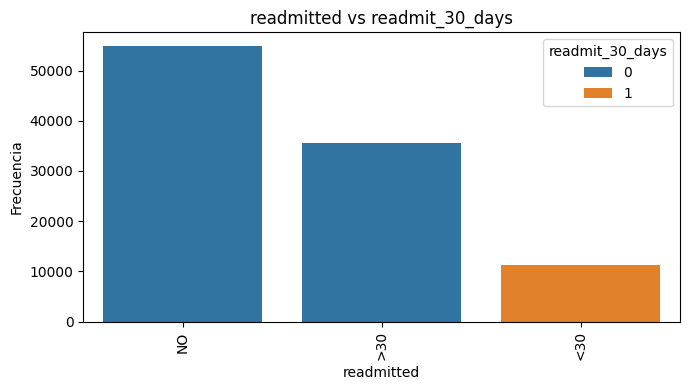

In [56]:
#lo representamos en gráficos
for col in category_columns:
    
    if col != "readmit_30_days":
        
        plt.figure(figsize=(7,4))
        sns.countplot(data=df, x=col, hue="readmit_30_days")
        
        plt.title(f"{col} vs readmit_30_days")
        plt.xlabel(col)
        plt.ylabel("Frecuencia")
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()

In [65]:
#hacemos chi2 y el p-value y hacemos una tabla
from scipy.stats import chi2_contingency
import pandas as pd

resultados_chi2 = []

for col in category_columns:
    
    if col != "readmit_30_days":
        # tabla de contingencia
        tabla = pd.crosstab(df[col], df["readmit_30_days"])
        #test chi2
        chi2, p, dof, expected = chi2_contingency(tabla)

        #decision sobre p-value
        decision = "Se podría descartar" if p > 0.05 else "Relacionada con la variable objetivo"
        
        resultados_chi2.append({
            "variable": col,
            "chi2": chi2,
            "p_value": p,
            "decision": decision
        })
#convertir a dataframe
resultados_chi2 = pd.DataFrame(resultados_chi2)

# redondear a 4 decimales
resultados_chi2["chi2"] = resultados_chi2["chi2"].round(4)
resultados_chi2["p_value"] = resultados_chi2["p_value"].round(4)

# ordenar por p_value
resultados_chi2 = resultados_chi2.sort_values("p_value")
resultados_chi2

,variable,chi2,p_value,decision
0,age,45.4639,0.0000,Relacionada con la variable objetivo
1,discharge_disposition_id,514.2874,0.0000,Relacionada con la variable objetivo
2,readmit_binary,14951.3303,0.0000,Relacionada con la variable objetivo
4,diabetesMed,74.6694,0.0000,Relacionada con la variable objetivo
6,had_inpatient_days,1506.8337,0.0000,Relacionada con la variable objetivo
5,admission_source_id,38.7704,0.0000,Relacionada con la variable objetivo
7,primary_diagnosis,76.5887,0.0000,Relacionada con la variable objetivo
8,medical_specialty,74.6409,0.0000,Relacionada con la variable objetivo
15,change,38.5961,0.0000,Relacionada con la variable objetivo
10,had_outpatient_days,122.6794,0.0000,Relacionada con la variable objetivo


Las variables cuyo p-value es superior a 0.05 no muestran evidencia de relación con la variable objetivo, por lo que podrían considerarse menos relevantes y podrían descartarse en etapas posteriores del análisis.